# Контрольная работа №1. Вариант 2

Правила обучения: Хебб и Уидроу–Хофф.

Сравниваю четыре варианта Хебба и дельта-правило Уидроу–Хоффа на линейных данных с шумом. Проверю, как влияют нормировка, размер входов и скорость обучения. В конце добавлю сигмоиду. Использую NumPy, Pandas и Matplotlib.

## 1. Правила обучения

В задании не уточняется, какую именно версию Хебба нужно взять. Поэтому я проверяю два варианта, оба с нормировкой и без неё. Это позволяет сравнить обучение с правильным ответом и без него.

Линейный нейрон: $\hat y=w_1x_1+w_2x_2+b$.

**Хебб без учителя:** $w_i'=w_i+\eta_Hx_i\hat y$, $b'=b+\eta_H\hat y$. Для обновления нужен только выход самого нейрона. Правильный ответ не используется.

**Хебб с учителем (с целевым сигналом):** $w_i'=w_i+\eta_Hx_i y$, $b'=b+\eta_H y$. Здесь вместо выхода нейрона в поправке используется правильный ответ $y$. Это одна из версий правила с учителем, **не** обновление по ошибке и **не** знаковое правило из лекции.

**Нормировка:** после каждого обновления ограничиваю длину всего вектора $(w_1,w_2,b)$ радиусом $R$. Если длина больше $R$, умножаю все параметры на $R/\|\theta\|$. Это не даёт весам бесконечно расти, но не гарантирует точных предсказаний.

**Уидроу–Хофф:** $w_i'=w_i+\eta_Wx_i(y-\hat y)$, $b'=b+\eta_W(y-\hat y)$. В отличие от Хебба с учителем, он учитывает **разность** между правильным ответом и предсказанием. Это градиентный спуск для половины MSE.

Для приближения непрерывной функции использую линейный выход. Пороговый нейрон Маккалока–Питтса выдаёт дискретные значения и для такой регрессии не подходит. Сигмоиду исследую отдельно в задании 5.

Перед обучением вычитаю только среднее входов, найденное на train: $z=x-\overline x$. Тогда $\hat y=z^Tw+b$. Смещение $b$ обучается по выбранному правилу, а не вычисляется через среднее правильных ответов.

### Небольшой расчёт вручную

Возьмём $x=(1,1)$, $w=(0.2,0.1)$, $b=0.1$, $\eta=0.1$, правильный ответ $y=1.5$.

Предсказание: $\hat y=0.2+0.1+0.1=0.4$.

- Хебб без учителя: поправка к каждому весу $0.1\cdot0.4=0.04$, к $b$ тоже $0.04$. Получаем $w'=(0.24,0.14)$, $b'=0.14$.
- Хебб с учителем: поправка $0.1\cdot1.5=0.15$. Получаем $w'=(0.35,0.25)$, $b'=0.25$.
- Уидроу–Хофф: ошибка $1.5-0.4=1.1$, поправка $0.11$. Получаем $w'=(0.31,0.21)$, $b'=0.21$.

Для обеих версий Хебба нормировка делается одинаково. Например, если $R=3$, а параметры равны $(4,3,0)$, то их длина $5$. Умножаем на $3/5$ и получаем $(2.4,1.8,0)$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEEDS = [3, 8, 15, 21, 34, 42, 57]
NOISES = [0.1, 0.5, 1.2]
EPOCHS = 160
LR_HEBB = 0.035
LR_DELTA = 0.15
RADIUS = 3.0

METHODS = [
    'Хебб без учителя',
    'Хебб без учителя (норма)',
    'Хебб с учителем',
    'Хебб с учителем (норма)',
    'Уидроу–Хофф',
]
COLORS = ['tab:red', 'tab:blue', 'tab:orange', 'tab:purple', 'tab:green']
SHORT_NAMES = ['Без уч.', 'Без уч. + норма', 'С уч.', 'С уч. + норма', 'Дельта']

np.set_printoptions(precision=4, suppress=True)
print('Seed:', SEEDS)
print('Шум:', NOISES)
print('Методы:', ', '.join(METHODS))

Seed: [3, 8, 15, 21, 34, 42, 57]
Шум: [0.1, 0.5, 1.2]
Методы: Хебб без учителя, Хебб без учителя (норма), Хебб с учителем, Хебб с учителем (норма), Уидроу–Хофф


## 2. Данные с тремя уровнями шума

Создаю данные по формуле $y=2x_1-1.2x_2+0.7+\varepsilon$. Шум $\varepsilon$ имеет нормальное распределение со средним 0. Проверяю стандартные отклонения $\sigma=0.1$, $0.5$ и $1.2$.

Для всех методов входы и деление на train/test одинаковые. Поэтому можно сравнивать результаты на одних и тех же данных.

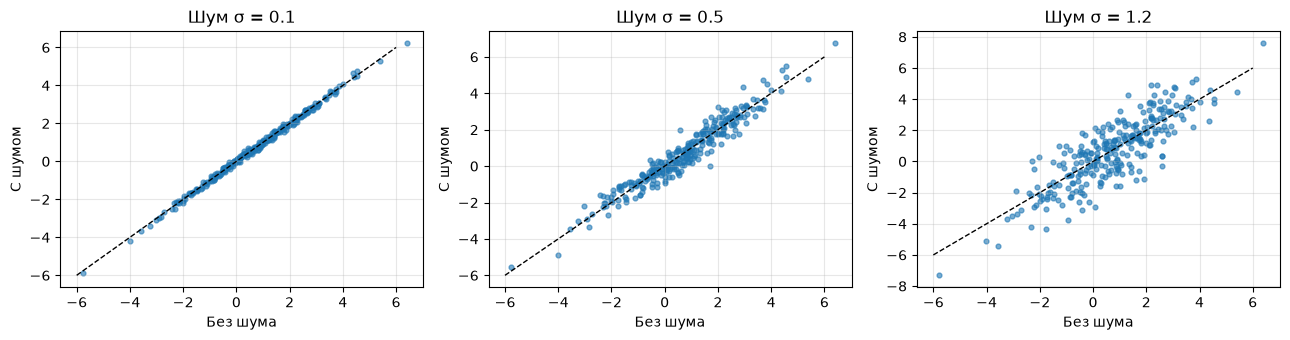

In [2]:
# Создаём общие признаки и фиксированное разделение на train/test.
rng = np.random.default_rng(2026)
N = 400
x1 = rng.normal(0, 1, N)
x2 = 0.4 * x1 + 0.7 * rng.normal(0, 1, N)
X_all = np.column_stack([x1, x2])
y_clean = 2 * x1 - 1.2 * x2 + 0.7

indices = np.random.default_rng(10).permutation(N)
train_idx = indices[:280]
test_idx = indices[280:]


def make_data(noise):
    # Добавляет заданный шум к одной и той же линейной функции.
    noise_rng = np.random.default_rng(4000 + int(noise * 100))
    y = y_clean + noise_rng.normal(0, noise, N)
    return X_all[train_idx], y[train_idx], X_all[test_idx], y[test_idx]


fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, noise in zip(axes, NOISES):
    X_train, y_train, _, _ = make_data(noise)
    ax.scatter(y_clean[train_idx], y_train, s=12, alpha=0.6)
    ax.plot([-6, 6], [-6, 6], 'k--', lw=1)
    ax.set_title(f'Шум σ = {noise}')
    ax.set_xlabel('Без шума')
    ax.set_ylabel('С шумом')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Вывод по данным: при σ = 0.1 точки находятся близко к правильной линии, а при σ = 1.2 разброс заметно больше. На более шумных данных точно предсказывать значения сложнее.

### Функции обучения

За одну эпоху считаю среднее изменение параметров по всей train-выборке, а затем один раз обновляю веса. Все пять методов начинают с одинаковых параметров при одном и том же `seed`.

У Хебба без учителя в поправке стоит $\hat y$, у Хебба с учителем — правильное $y$, а у Уидроу–Хоффа — ошибка $y-\hat y$. Обе нормированные версии после обновления ограничивают длину $(w_1,w_2,b)$.

In [3]:
def mse(y_true, y_pred):
    # Средний квадрат ошибки.
    return np.mean((y_true - y_pred) ** 2)


def predict_linear(X, w, b, mean_x):
    # Предсказание линейного нейрона.
    return (X - mean_x) @ w + b


def train_linear(X_train, y_train, X_test, y_test, method, seed,
                 epochs=EPOCHS, lr=None, radius=RADIUS,
                 lr_bias=None, weight_scale=1):
    # Обучает нейрон и сохраняет ошибки после каждой эпохи
    mean_x = X_train.mean(axis=0)
    X = X_train - mean_x

    rng = np.random.default_rng(seed)
    w = rng.normal(0, 0.25, X.shape[1]) / weight_scale
    b = rng.normal(0, 0.25)

    if lr is None:
        lr = LR_DELTA if method == 'Уидроу–Хофф' else LR_HEBB
    if lr_bias is None:
        lr_bias = lr

    train_losses, test_losses, norms, biases = [], [], [], []
    diverged = False

    for epoch in range(epochs + 1):
        out = X @ w + b
        pred_test = predict_linear(X_test, w, b, mean_x)
        if not np.isfinite(out).all() or np.max(np.abs(out)) > 1e8:
            diverged = True
            break

        train_losses.append(mse(y_train, out))
        test_losses.append(mse(y_test, pred_test))
        norms.append(np.linalg.norm(np.append(w, b)))
        biases.append(b)
        if epoch == epochs:
            break

        if method == 'Уидроу–Хофф':
            # Дельта-правило: поправка зависит от ошибки.
            signal = y_train - out
        elif method.startswith('Хебб с учителем'):
            # Вариант с учителем: используем правильный ответ.
            signal = y_train
        else:
            # Без учителя: используем выход самого нейрона.
            signal = out

        dw = X.T @ signal / len(X)
        db = signal.mean()
        new_w = w + lr * dw
        new_b = b + lr_bias * db

        if '(норма)' in method:
            length = np.linalg.norm(np.append(new_w, new_b))
            if length > radius:
                new_w *= radius / length
                new_b *= radius / length

        # Проверка не даёт переполнению испортить следующие эпохи.
        if (not np.isfinite(new_w).all() or not np.isfinite(new_b) or
                np.max(np.abs(new_w)) > 1e10 or abs(new_b) > 1e10):
            diverged = True
            break
        w, b = new_w, new_b

    return {
        'w': w, 'b': b, 'mean_x': mean_x,
        'train_loss': np.array(train_losses),
        'test_loss': np.array(test_losses),
        'norms': np.array(norms), 'biases': np.array(biases),
        'epochs_done': len(train_losses) - 1, 'diverged': diverged,
    }


X_train, y_train, X_test, y_test = make_data(0.5)
for method in METHODS:
    r = train_linear(X_train, y_train, X_test, y_test, method, SEEDS[0])
    print(method, '| Test MSE:', round(r['test_loss'][-1], 4),
          '| веса:', np.round(r['w'], 3), '| b:', round(r['b'], 3))

Хебб без учителя | Test MSE: 11069.5496 | веса: [70.692 36.071] | b: 25.685
Хебб без учителя (норма) | Test MSE: 7.2951 | веса: [2.542 1.297] | b: 0.924
Хебб с учителем | Test MSE: 89.6318 | веса: [ 9.184 -0.356] | b: 4.123
Хебб с учителем (норма) | Test MSE: 3.5265 | веса: [2.727 0.026] | b: 1.251
Уидроу–Хофф | Test MSE: 0.1781 | веса: [ 1.995 -1.133] | b: 0.718


### 2.1. Сравнение при разном шуме и семи seed

Для каждого уровня шума обучаю все пять методов с семью разными начальными весами. Всего получается $3\cdot5\cdot7=105$ запусков. По тестовой MSE считаю среднее и стандартное отклонение, а затем строю графики. Для ошибок использую логарифмическую шкалу: без нормировки они могут сильно увеличиваться.

In [4]:
results = {}
rows = []
for noise in NOISES:
    X_train, y_train, X_test, y_test = make_data(noise)
    for method in METHODS:
        runs = [train_linear(X_train, y_train, X_test, y_test, method, seed)
                for seed in SEEDS]
        results[(noise, method)] = runs
        scores = [run['test_loss'][-1] for run in runs]
        rows.append({
            'Шум': noise, 'Метод': method,
            'Test MSE средняя': np.mean(scores),
            'Test MSE ст. откл.': np.std(scores),
            'Мин. MSE': min(scores), 'Макс. MSE': max(scores),
            'Средняя норма': np.mean([run['norms'][-1] for run in runs]),
            'Расходится, запусков': sum(run['diverged'] for run in runs),
        })

summary = pd.DataFrame(rows)
print(summary.round(4).to_string(index=False))

 Шум                    Метод  Test MSE средняя  Test MSE ст. откл.  Мин. MSE   Макс. MSE  Средняя норма  Расходится, запусков
 0.1         Хебб без учителя       114608.8556         125317.9703 8393.2042 372282.8024       230.9449                     0
 0.1 Хебб без учителя (норма)           17.9063              9.5612    6.2061     30.7298         3.0000                     0
 0.1          Хебб с учителем           79.9462              6.5693   67.4477     86.6374         9.5198                     0
 0.1  Хебб с учителем (норма)            3.1909              0.0988    3.0764      3.3905         3.0000                     0
 0.1              Уидроу–Хофф            0.0116              0.0000    0.0116      0.0116         2.4402                     0
 0.5         Хебб без учителя       114608.1201         125309.7162 8394.7158 372264.7065       230.9449                     0
 0.5 Хебб без учителя (норма)           18.1315              9.4789    6.5880     30.7999         3.0000       

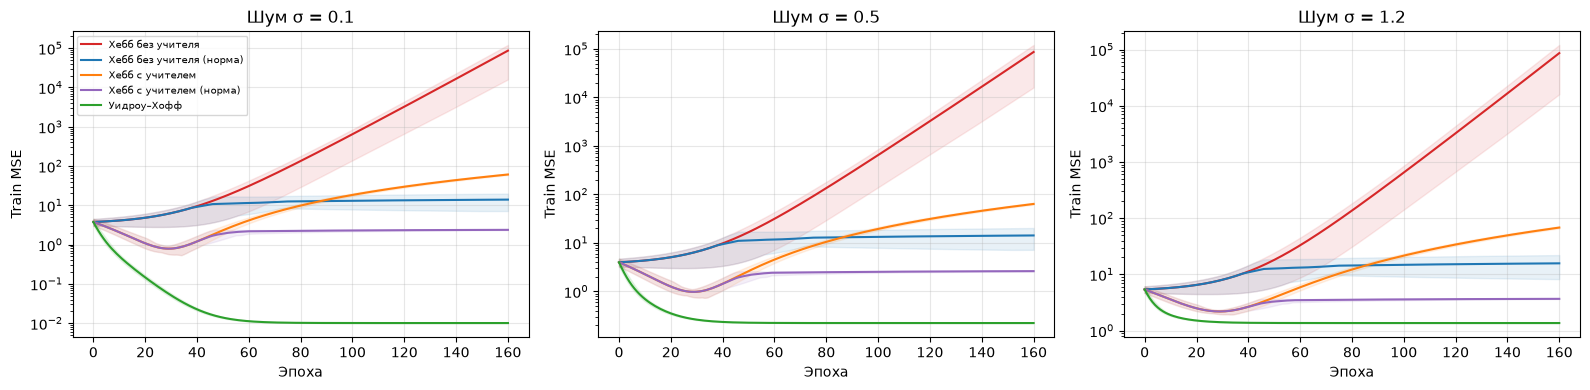

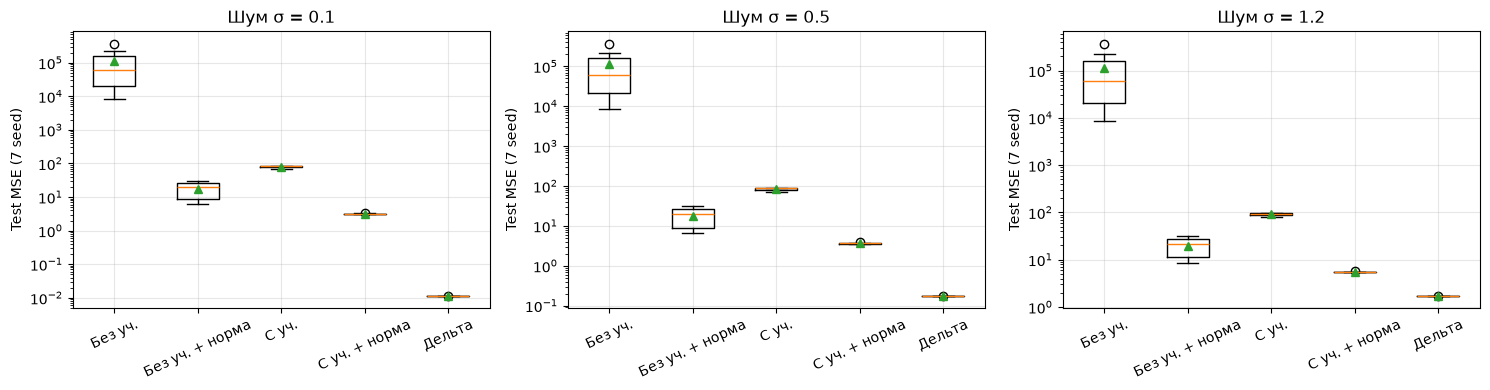

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, noise in zip(axes, NOISES):
    for method, color in zip(METHODS, COLORS):
        runs = results[(noise, method)]
        # Если обучение остановлено, берём общий участок кривых.
        count = min(len(run['train_loss']) for run in runs)
        curves = np.array([run['train_loss'][:count] for run in runs])
        epochs = np.arange(count)
        ax.plot(epochs, curves.mean(axis=0), label=method, color=color)
        ax.fill_between(epochs, np.percentile(curves, 25, axis=0),
                        np.percentile(curves, 75, axis=0), color=color, alpha=0.1)
    ax.set_yscale('log')
    ax.set_title(f'Шум σ = {noise}')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Train MSE')
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, noise in zip(axes, NOISES):
    data = [[run['test_loss'][-1] for run in results[(noise, method)]]
            for method in METHODS]
    ax.boxplot(data, showmeans=True)
    ax.set_xticks(range(1, len(SHORT_NAMES) + 1))
    ax.set_xticklabels(SHORT_NAMES, rotation=25)
    ax.set_yscale('log')
    ax.set_title(f'Шум σ = {noise}')
    ax.set_ylabel('Test MSE (7 seed)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Вывод по обучению: Уидроу–Хофф старается уменьшать MSE и поэтому обычно ближе всех к правильным ответам. У Хебба без учителя веса могут быстро расти, потому что его поправка зависит от собственного выхода. У Хебба с учителем поправка зависит от правильных ответов, но **не от ошибки**, поэтому он тоже не обязан приближаться к минимуму MSE. Нормировка не даёт параметрам расти бесконечно, однако сама по себе не исправляет предсказания.

Например, при шуме $\sigma=0.5$ средняя Test MSE у Хебба без учителя получилась около 114608 без нормы и 18.13 с нормой. У Хебба с учителем — около 84.18 и 3.65 соответственно, а у Уидроу–Хоффа — 0.178.

### 2.2. Предсказания обученных нейронов

На графиках сравниваю правильные ответы и предсказания на test. Чем ближе точки к пунктирной линии, тем лучше. В каждой строке один уровень шума, в каждом столбце — один метод. Беру одинаковый `seed = 3`; общая статистика по семи запускам уже показана выше.

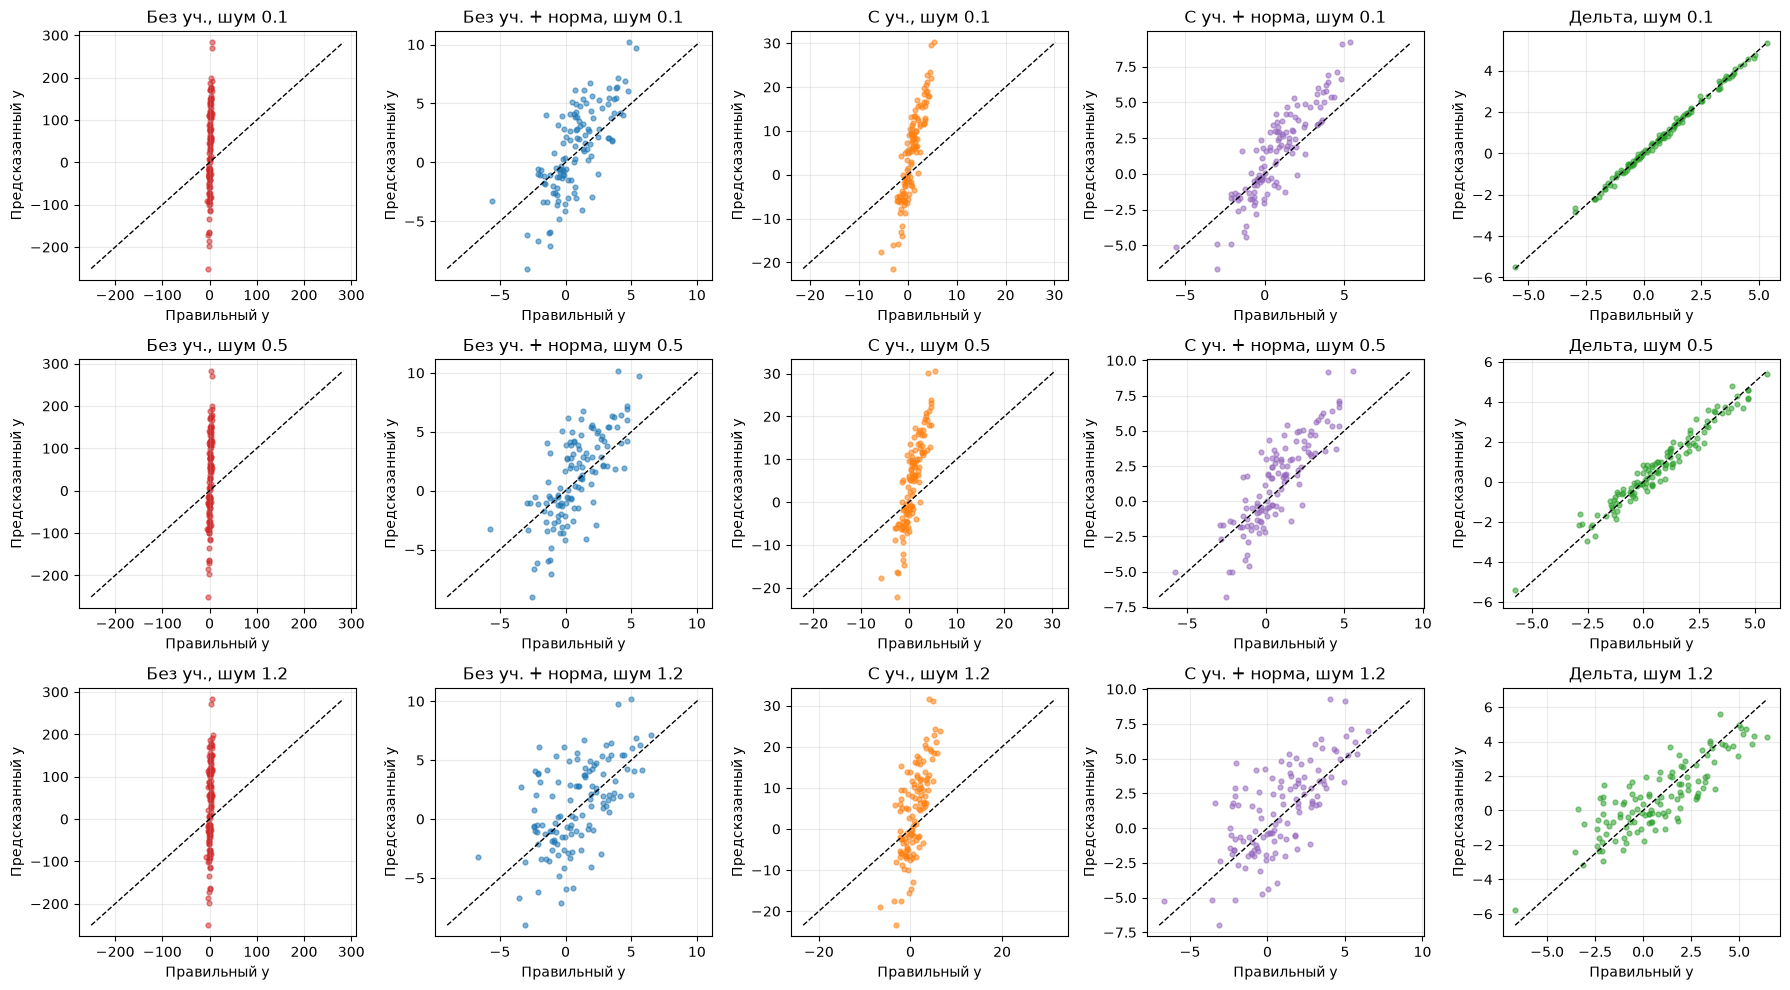

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for i, noise in enumerate(NOISES):
    X_train, y_train, X_test, y_test = make_data(noise)
    for j, (method, color) in enumerate(zip(METHODS, COLORS)):
        run = results[(noise, method)][0]
        prediction = predict_linear(X_test, run['w'], run['b'], run['mean_x'])
        ax = axes[i, j]
        ax.scatter(y_test, prediction, s=12, alpha=0.55, color=color)
        mn, mx = min(y_test.min(), prediction.min()), max(y_test.max(), prediction.max())
        ax.plot([mn, mx], [mn, mx], 'k--', linewidth=1)
        ax.set_title(f'{SHORT_NAMES[j]}, шум {noise}')
        ax.set_xlabel('Правильный y')
        ax.set_ylabel('Предсказанный y')
        ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Вывод по предсказаниям: при хорошем обучении точки располагаются около пунктирной линии. Уидроу–Хофф обычно справляется лучше, потому что исправляет ошибку. У Хебба оба варианта учатся по произведению входа и сигнала, поэтому без нормировки могут выдавать слишком большие ответы; нормировка ограничивает их масштаб. Чем больше шум, тем заметнее разброс.

## 3. Сходимость и рост весов

После центрирования среднее входов $z=x-\overline x$ равно нулю. Обозначу их ковариационную матрицу через $C=E[zz^T]$. Выход нейрона: $\hat y=w^Tz+b$.

**Хебб без учителя.** Среднее изменение весов: $\Delta w=\eta_HE[z\hat y]=\eta_HCw$. Поэтому $w_{n+1}=(I+\eta_HC)w_n$. В направлении собственного вектора $C$ с собственным значением $\lambda>0$ вес умножается на $1+\eta_H\lambda$ на каждой эпохе и может расти неограниченно. Смещение: $b_{n+1}=(1+\eta_H)b_n$.

**Хебб с учителем.** Средняя поправка уже не зависит от текущих весов: $\Delta w=\eta_HE[zy]$, $\Delta b=\eta_HE[y]$. При одинаковых данных это постоянные значения. Поэтому $w_n=w_0+n\eta_HE[zy]$ и $b_n=b_0+n\eta_HE[y]$. Рост здесь **линейный**, если эти средние не равны нулю, а не экспоненциальный, как у Хебба без учителя.

Нормировка ограничивает общую длину $(w_1,w_2,b)$ числом $R$. Но это не означает, что веса становятся правильными. Для Хебба без учителя направление определяется в основном направлениями наибольшего роста входов и смещения, а для варианта с учителем — направлением средней поправки $E[zy]$ и $E[y]$.

**Уидроу–Хофф.** Поправка содержит ошибку $y-\hat y$. В точке минимума MSE средний градиент нулевой. Для матрицы $Z$ со столбцом единиц решение удовлетворяет $Z^TZ\theta=Z^Ty$. Найти его можно через `np.linalg.lstsq`.

**Нормированный Хебб без учителя.** Мы уже получили формулы $w_{n+1}=(I+\eta_H C)w_n$ и $b_{n+1}=(1+\eta_H)b_n$. Веса быстрее всего растут в направлении собственного вектора матрицы $C$ с наибольшим собственным значением $\lambda_{\max}$.

В нашем случае $\lambda_{\max}\approx1.23$. Это больше 1, которое соответствует обновлению смещения. Поэтому при достаточно долгом обучении главное направление весов начинает преобладать, а доля смещения уменьшается.

С нормировкой получаем $w_n\rightarrow\pm Rv_{\max}$ и $b_n\rightarrow0$, где $R=3$, а $v_{\max}$ — главный собственный вектор единичной длины. Знак зависит от начальных весов. Такой результат получается, если у начальных весов есть ненулевая составляющая в главном направлении.

**Нормированный Хебб с учителем.** Здесь средняя поправка постоянна: $g=(E[zy],E[y])$. Она включает изменения обоих весов и смещения. На каждой эпохе добавляем $\eta_H g$, поэтому параметры постепенно смещаются в направлении этого вектора.

При $g\ne0$ в нашем эксперименте нормированные параметры стремятся к $\theta_n\rightarrow R\frac{g}{\|g\|}$, где $\theta=(w_1,w_2,b)$.

Получается, что обе версии Хебба с нормировкой приближаются к определённым направлениям, но по разным причинам. У Хебба без учителя направление определяется ковариацией входов, а у Хебба с учителем — средней поправкой по правильным ответам. При этом ни один вариант не гарантирует минимальную MSE.

In [7]:
X_train, y_train, X_test, y_test = make_data(0.5)
mean_x = X_train.mean(axis=0)
mean_y = y_train.mean()
Xc = X_train - mean_x
C = Xc.T @ Xc / len(Xc)
eigenvalues, eigenvectors = np.linalg.eigh(C)
main_direction = eigenvectors[:, -1]

# Минимум MSE линейной модели (метод наименьших квадратов).
w_best = np.linalg.lstsq(Xc, y_train - mean_y, rcond=None)[0]
b_best = mean_y
pred_best = predict_linear(X_test, w_best, b_best, mean_x)

print('Среднее центрированных входов:', Xc.mean(axis=0))
print('Собственные значения C:', eigenvalues.round(4))
print('Коэффициенты исходной функции:', [2, -1.2, 0.7])
print('Минимум MSE: w =', w_best.round(4), 'b =', round(b_best, 4))
print('Test MSE в точке минимума:', round(mse(y_test, pred_best), 5))

for method in METHODS:
    run = results[(0.5, method)][0]
    w = run['w']
    cosine = abs(w @ main_direction) / (np.linalg.norm(w) + 1e-12)
    print(method, '| норма:', round(run['norms'][-1], 4),
          '| b:', round(run['b'], 4),
          '| близость w к главной оси C:', round(cosine, 4))

# Сверяем рост b при фиксированных данных и без нормировки.
start_b = np.random.default_rng(SEEDS[0]).normal(0, 0.25, 3)[-1]
r_no = results[(0.5, 'Хебб без учителя')][0]
r_yes = results[(0.5, 'Хебб с учителем')][0]
theory_no = start_b * (1 + LR_HEBB) ** r_no['epochs_done']
theory_yes = start_b + r_yes['epochs_done'] * LR_HEBB * mean_y
print('Без учителя, b: расчёт', round(theory_no, 5),
      '/ эксперимент', round(r_no['b'], 5))
print('С учителем, b: расчёт', round(theory_yes, 5),
      '/ эксперимент', round(r_yes['b'], 5))

# Проверяем, что при обучении с учителем веса меняются линейно.
initial_w = np.random.default_rng(SEEDS[0]).normal(0, 0.25, 2)
expected_w = initial_w + r_yes['epochs_done'] * LR_HEBB * (Xc.T @ y_train / len(Xc))
print('С учителем, w: расчёт', expected_w.round(4),
      '/ эксперимент', r_yes['w'].round(4))

Среднее центрированных входов: [ 0. -0.]
Собственные значения C: [0.386  1.2297]
Коэффициенты исходной функции: [2, -1.2, 0.7]
Минимум MSE: w = [ 1.9948 -1.133 ] b = 0.7176
Test MSE в точке минимума: 0.17809
Хебб без учителя | норма: 83.4158 | b: 25.6847 | близость w к главной оси C: 0.9962
Хебб без учителя (норма) | норма: 3.0 | b: 0.9237 | близость w к главной оси C: 0.9962
Хебб с учителем | норма: 10.0731 | b: 4.1228 | близость w к главной оси C: 0.8263
Хебб с учителем (норма) | норма: 3.0 | b: 1.2506 | близость w к главной оси C: 0.8524
Уидроу–Хофф | норма: 2.4037 | b: 0.7176 | близость w к главной оси C: 0.4748
Без учителя, b: расчёт 25.68473 / эксперимент 25.68473
С учителем, b: расчёт 4.12284 / эксперимент 4.12284
С учителем, w: расчёт [ 9.1838 -0.3564] / эксперимент [ 9.1838 -0.3564]


Хебб без учителя (норма) : на 160-й эпохе 0.9478 , на 640-й 1.0
Хебб с учителем (норма) : на 160-й эпохе 0.9998 , на 640-й 1.0


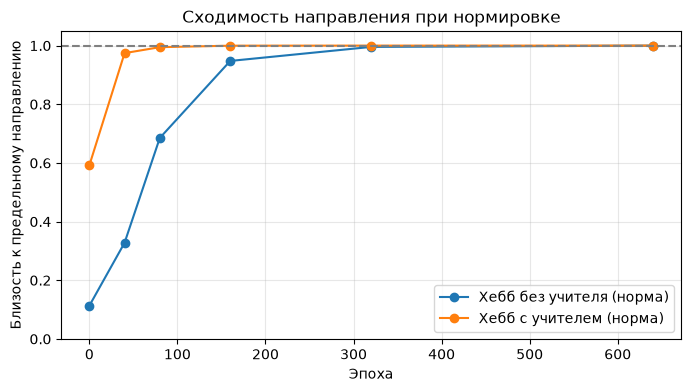

In [8]:
# Проверяем направление параметров нормированных версий Хебба.

main_vector = np.append(main_direction, 0.0)

target_vector = np.append(Xc.T @ y_train / len(Xc), y_train.mean())
target_vector /= np.linalg.norm(target_vector)

check_epochs = [0, 40, 80, 160, 320, 640]

plt.figure(figsize=(8, 4))

for method, direction in [
    ('Хебб без учителя (норма)', main_vector),
    ('Хебб с учителем (норма)', target_vector),
]:
    similarity = []

    for epochs in check_epochs:
        run = train_linear(
            X_train, y_train, X_test, y_test,
            method, SEEDS[0], epochs=epochs
        )

        theta = np.append(run['w'], run['b'])

        cosine = abs(theta @ direction) / np.linalg.norm(theta)
        similarity.append(cosine)

    plt.plot(check_epochs, similarity, marker='o', label=method)

    print(method,
          ': на 160-й эпохе', round(similarity[3], 4),
          ', на 640-й', round(similarity[-1], 4))

plt.axhline(1, color='gray', linestyle='--')

plt.xlabel('Эпоха')
plt.ylabel('Близость к предельному направлению')
plt.title('Сходимость направления при нормировке')

plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

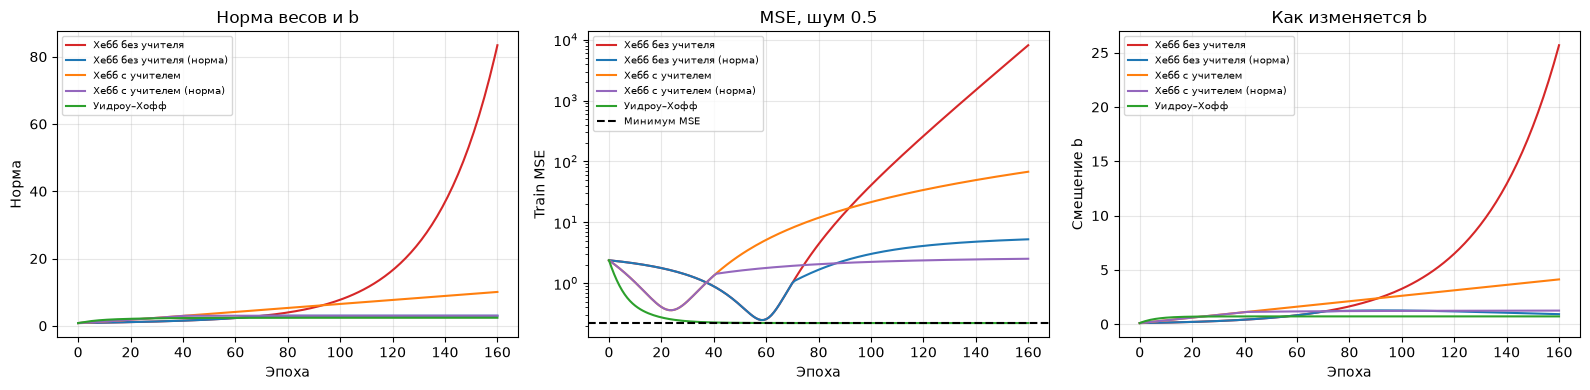

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for method, color in zip(METHODS, COLORS):
    run = results[(0.5, method)][0]
    axes[0].plot(run['norms'], label=method, color=color)
    axes[1].plot(run['train_loss'], label=method, color=color)
    axes[2].plot(run['biases'], label=method, color=color)
axes[0].set_title('Норма весов и b')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Норма')
axes[1].set_title('MSE, шум 0.5')
axes[1].axhline(mse(y_train, Xc @ w_best + b_best),
                linestyle='--', color='black', label='Минимум MSE')
axes[1].set_yscale('log')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Train MSE')
axes[2].set_title('Как изменяется b')
axes[2].set_xlabel('Эпоха')
axes[2].set_ylabel('Смещение b')
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Вывод по сходимости: нулевое среднее входов не спасает Хебба от роста весов. У версии без учителя рост может быть геометрическим, а у версии с учителем при фиксированных данных — линейным.

Нормировка ограничивает длину параметров. При этом Хебб без учителя постепенно приближается к главному собственному направлению ковариационной матрицы, а Хебб с учителем — к направлению средней поправки.

Это подтвердилось экспериментом: после 640 эпох близость к ожидаемому направлению у обоих методов практически равна 1.

Но правильные коэффициенты функции это не гарантирует. Уидроу–Хофф лучше подходит для нашей задачи, потому что использует ошибку предсказания и стремится к минимуму MSE.

## 4. Увеличение масштаба признаков в 10 и 100 раз

Умножаю оба входа на $s=1$, $10$ и $100$, но правильные ответы оставляю прежними. Сначала шаг обучения не меняю и смотрю на все пять методов.

У центрированных входов ковариация после масштабирования равна $C_{new}=s^2C$. Поэтому особенно сильно растут поправки у Хебба без учителя. Для Хебба с учителем $E[zy]$ увеличивается в $s$ раз, но изменение самого предсказания из-за поправки тоже связано с масштабом входов. У Уидроу–Хоффа большой масштаб тоже может сделать обновления неустойчивыми.

Затем отдельно проверяю уменьшение шага у Уидроу–Хоффа: для весов $\eta_w'=\eta_W/s^2$, а для смещения прежний шаг $\eta_b=\eta_W$. Начальные веса делю на $s$, чтобы сравнивать обучение при одинаковых начальных предсказаниях.

 Масштаб                    Метод  Эпох сделано  Расходится     Test MSE
       1         Хебб без учителя           160       False 1.106955e+04
       1 Хебб без учителя (норма)           160       False 7.295150e+00
       1          Хебб с учителем           160       False 8.963176e+01
       1  Хебб с учителем (норма)           160       False 3.526470e+00
       1              Уидроу–Хофф           160       False 1.781000e-01
      10         Хебб без учителя            10        True 4.525974e+14
      10 Хебб без учителя (норма)           160       False 1.405884e+03
      10          Хебб с учителем           160       False 1.011608e+06
      10  Хебб с учителем (норма)           160       False 1.089790e+03
      10              Уидроу–Хофф             6        True 3.260871e+13
     100         Хебб без учителя             2        True 5.905699e+12
     100 Хебб без учителя (норма)           160       False 1.497153e+05
     100          Хебб с учителем           160    

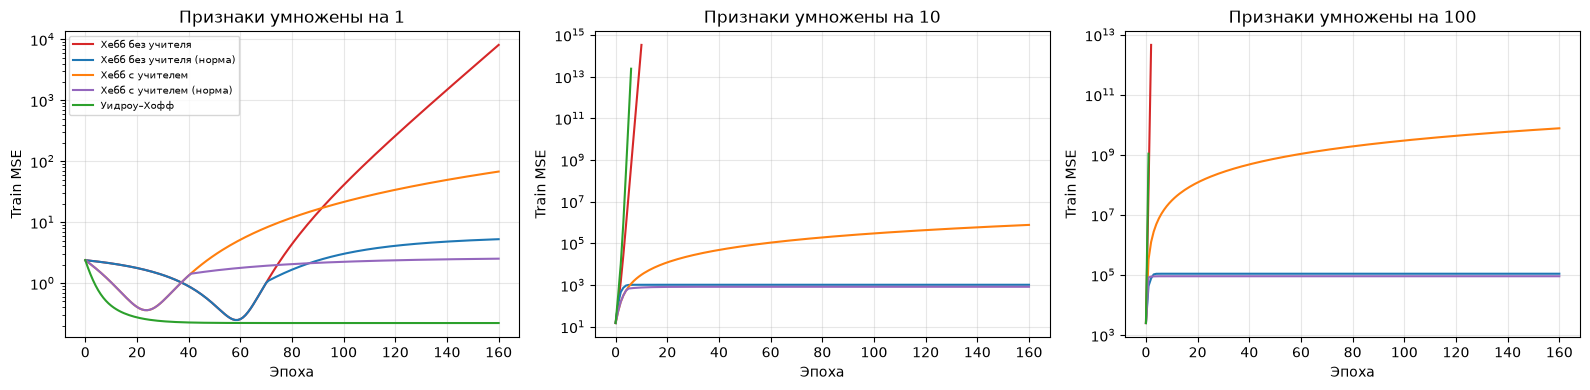

In [10]:
X_train, y_train, X_test, y_test = make_data(0.5)
SCALES = [1, 10, 100]
fixed = {}
scaled_rows = []
for scale in SCALES:
    for method in METHODS:
        run = train_linear(scale * X_train, y_train, scale * X_test,
                           y_test, method, seed=SEEDS[0], epochs=EPOCHS)
        fixed[(scale, method)] = run
        scaled_rows.append({
            'Масштаб': scale, 'Метод': method,
            'Эпох сделано': run['epochs_done'],
            'Расходится': run['diverged'],
            'Test MSE': run['test_loss'][-1],
        })

print(pd.DataFrame(scaled_rows).round(5).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, scale in zip(axes, SCALES):
    for method, color in zip(METHODS, COLORS):
        run = fixed[(scale, method)]
        ax.plot(run['train_loss'], label=method, color=color)
    ax.set_yscale('log')
    ax.set_title(f'Признаки умножены на {scale}')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Train MSE')
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

Вывод при неизменном шаге: чем больше признаки, тем сильнее скачки параметров. У методов без нормировки значения могут быстро вырасти, а дельта-правило при большом масштабе становится неустойчивым. В коде есть остановка при слишком больших выходах, чтобы избежать переполнения. Нормировка сохраняет границу для параметров, но при входах в 100 раз больше даже ограниченные веса могут давать очень большие предсказания.

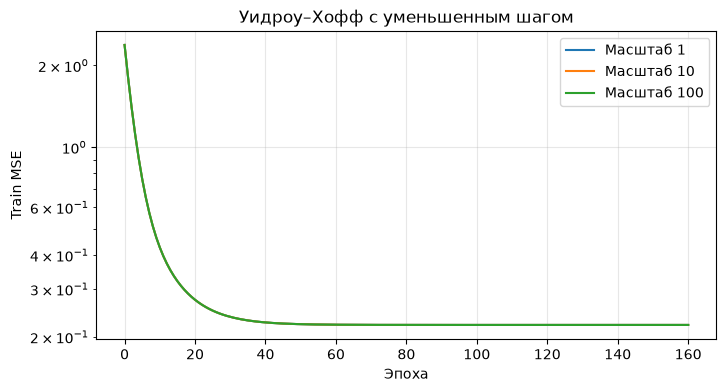

 Масштаб  Шаг весов  Шаг b  Test MSE
       1   0.150000   0.15  0.178096
      10   0.001500   0.15  0.178096
     100   0.000015   0.15  0.178096


In [11]:
# Подстраиваем шаг весов под масштаб для дельта-правила.
fig, ax = plt.subplots(figsize=(8, 4))
compensated = []
for scale in SCALES:
    run = train_linear(scale * X_train, y_train, scale * X_test, y_test,
                       'Уидроу–Хофф', seed=SEEDS[0], epochs=EPOCHS,
                       lr=LR_DELTA / scale**2,
                       lr_bias=LR_DELTA, weight_scale=scale)
    compensated.append({
        'Масштаб': scale, 'Шаг весов': LR_DELTA / scale**2,
        'Шаг b': LR_DELTA, 'Test MSE': run['test_loss'][-1]
    })
    ax.plot(run['train_loss'], label=f'Масштаб {scale}')
ax.set_yscale('log')
ax.set_title('Уидроу–Хофф с уменьшенным шагом')
ax.set_xlabel('Эпоха')
ax.set_ylabel('Train MSE')
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(pd.DataFrame(compensated).to_string(index=False))

Вывод после уменьшения шага: если разделить скорость обновления весов на $s^2$, а для смещения оставить её прежней, кривые Уидроу–Хоффа почти совпадают. Так что большие значения признаков нужно учитывать при подборе learning rate.

## 5. Сигмоида вместо линейного выхода

Сигмоида: $s(z) = 1 / (1 + exp(-z))$. Её производная: $s'(z) = s(z)*(1-s(z))$.

У линейного нейрона производная выхода по сумме равна 1, поэтому дельта-правило даёт правильный шаг для уменьшения MSE.

Если выход $y_pred = sigmoid(w*x+b)$, то для потерь $L = (1/2)*среднее((y_pred-y_true)²)$ правильный градиент по весам содержит дополнительный множитель $y_pred*(1-y_pred)$. Обычная формула без него уже не равна производной MSE.

Сначала проверяем это численно на маленьком примере, потом сравниваем обучение с правильной и упрощённой формулами. Цель — показать разницу в производных, а не обязательно добиться худшей MSE у упрощённой формулы.

In [12]:
def sigmoid(z):
    # Сигмоида, принимающая значения от 0 до 1
    z = np.clip(z, -40, 40)
    return 1 / (1 + np.exp(-z))


def sigmoid_loss(X, y, w, b):
    # Половина среднего квадрата ошибки для сигмоиды
    pred = sigmoid(X @ w + b)
    return 0.5 * mse(y, pred)


def sigmoid_grad(X, y, w, b, use_chain=True):
    # Вычисляет градиент с цепным правилом или без него.
    pred = sigmoid(X @ w + b)
    error = pred - y
    if use_chain:
        error = error * pred * (1 - pred)
    gw = X.T @ error / len(X)
    gb = error.mean()
    return gw, gb


def train_sigmoid(X, y, seed, use_chain, epochs=350, lr=0.3):
    # Обучает сигмоидный нейрон по двум вариантам формулы.
    w = np.random.default_rng(seed).normal(0, 0.25, X.shape[1])
    b = 0.0
    losses = []
    for epoch in range(epochs + 1):
        losses.append(sigmoid_loss(X, y, w, b))
        if epoch == epochs:
            break
        gw, gb = sigmoid_grad(X, y, w, b, use_chain=use_chain)
        w -= lr * gw
        b -= lr * gb
    return w, b, np.array(losses)


# Данные для сигмоиды: правильные ответы лежат между 0 и 1.
X_sig = X_all[train_idx]
X_sig_test = X_all[test_idx]
rng_sig = np.random.default_rng(141)
latent = 1.1 * X_all[:, 0] - 0.7 * X_all[:, 1] + 0.35
latent += rng_sig.normal(0, 0.35, N)
y_sig = sigmoid(latent[train_idx])
y_sig_test = sigmoid(latent[test_idx])

w0 = np.array([0.2, -0.3])
b0 = 0.15
correct_w, correct_b = sigmoid_grad(X_sig, y_sig, w0, b0, True)
simple_w, simple_b = sigmoid_grad(X_sig, y_sig, w0, b0, False)

# Проверка первой производной по w1 через разность потерь.
eps = 1e-5
w_plus = w0.copy()
w_minus = w0.copy()
w_plus[0] += eps
w_minus[0] -= eps
numeric = (sigmoid_loss(X_sig, y_sig, w_plus, b0) -
           sigmoid_loss(X_sig, y_sig, w_minus, b0)) / (2 * eps)

print('Численная производная по w1:', round(numeric, 7))
print('С цепным правилом:', round(correct_w[0], 7))
print('Без цепного правила:', round(simple_w[0], 7))

Численная производная по w1: -0.0356034
С цепным правилом: -0.0356034
Без цепного правила: -0.1452334


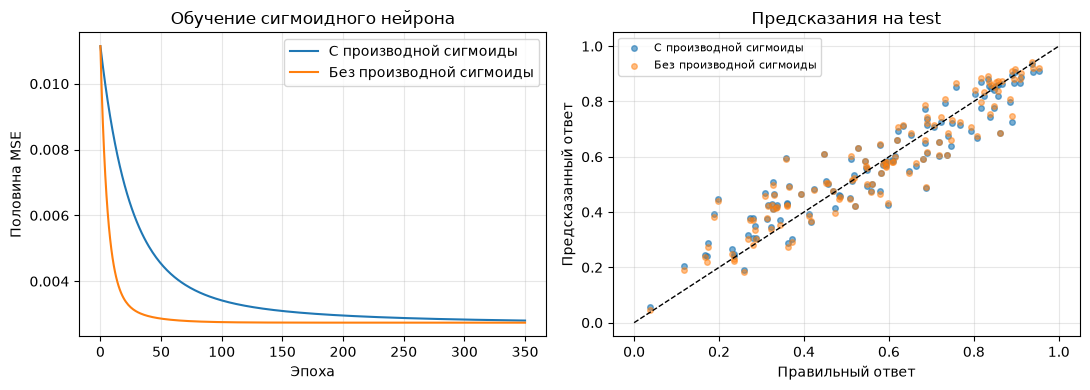

Test MSE с цепным правилом: 0.00685
Test MSE без цепного правила: 0.00652


In [13]:
w_correct, b_correct, curve_correct = train_sigmoid(
    X_sig, y_sig, seed=SEEDS[0], use_chain=True)
w_simple, b_simple, curve_simple = train_sigmoid(
    X_sig, y_sig, seed=SEEDS[0], use_chain=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(curve_correct, label='С производной сигмоиды')
axes[0].plot(curve_simple, label='Без производной сигмоиды')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Половина MSE')
axes[0].set_title('Обучение сигмоидного нейрона')
axes[0].legend()
axes[0].grid(alpha=0.3)

p_correct = sigmoid(X_sig_test @ w_correct + b_correct)
p_simple = sigmoid(X_sig_test @ w_simple + b_simple)
axes[1].scatter(y_sig_test, p_correct, s=16, alpha=0.6,
                label='С производной сигмоиды')
axes[1].scatter(y_sig_test, p_simple, s=16, alpha=0.5,
                label='Без производной сигмоиды')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('Правильный ответ')
axes[1].set_ylabel('Предсказанный ответ')
axes[1].set_title('Предсказания на test')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Test MSE с цепным правилом:', round(mse(y_sig_test, p_correct), 6))
print('Test MSE без цепного правила:', round(mse(y_sig_test, p_simple), 6))

Вывод по сигмоиде: численная производная по первому весу равна -0.0356034. Правильная формула даёт то же число, а упрощённая — -0.1452334. Значит, без производной сигмоиды мы уже не вычисляем точный градиент MSE. В нашем опыте обе формулы уменьшают ошибку, и упрощённая даже дала немного меньшую Test MSE за 350 эпох: она делает более крупные шаги. Это не делает её математически точной. При выходе сигмоиды около 0 или 1 правильный градиент уменьшается из-за насыщения.

## 6. Ответы на контрольные вопросы

**Когда правило Хебба применимо?** Когда хочется выделить совместно активные признаки и отклики, например при запоминании образов. Без учителя оно не требует правильных ответов. Версия с учителем использует целевой сигнал, но сама по себе не ищет минимум MSE. Для устойчивости часто нужна нормировка или изменение правила.

**Почему дельта-правило — частный случай Backpropagation?** Оно получается из производной ошибки по весам одного линейного нейрона. Backpropagation делает то же самое для сети из нескольких слоёв, передавая производные назад по цепному правилу.

**Почему влияет шум?** Чем больше случайная добавка в правильных ответах, тем сложнее предсказать их точно и тем выше тестовая MSE.

**Почему важно масштабировать признаки?** Размер входов влияет на величину поправок. При больших входах прежний шаг может оказаться слишком большим.

## Общие выводы

1. В задании не указана конкретная версия Хебба, поэтому я проверил четыре сочетания: с учителем и без, каждое с нормировкой и без неё. Для сравнения отдельно оставил Уидроу–Хоффа.

2. У Хебба без учителя поправка зависит от выхода нейрона. Даже при нулевом среднем входов веса могут расти очень быстро. У Хебба с учителем поправка зависит от целевого сигнала и при фиксированных данных может накапливаться линейно. Ни одна версия не минимизирует MSE напрямую.

3. Нормировка ограничивает длину весов и смещения, но не гарантирует правильные ответы. При этом Хебб без учителя постепенно приближается к главному собственному направлению ковариационной матрицы, а Хебб с учителем — к направлению средней поправки. Это подтвердилось экспериментом. Уидроу–Хофф использует ошибку предсказания и поэтому лучше подходит для восстановления линейной функции.

4. С увеличением шума тестовая ошибка растёт. Семь разных начальных значений весов позволяют оценить разброс результатов.

5. При увеличении входов в 10 и 100 раз обучение без изменения шага может стать неустойчивым. Подбор learning rate помогает это исправить.

6. Для сигмоиды нужно учитывать производную активации при вычислении градиента MSE. Это проверено аналитически и численно.